# Deuxième source de données : les notes Metacritic
### Projet final de Data Wrangling : Partie IV, nettoyage et analyse exploratoire de la deuxième base

Le client a demandé d'ajouter une deuxième base à l'analyse des ventes. Ce notebook la nettoie et l'explore en suivant la même démarche que `projet_final.ipynb` (Partie I : nettoyage ; Partie II : EDA). La Partie V relie cette base aux ventes et croise les deux.

| | |
|---|---|
| **Base** | *Video Game Sales with Ratings* (Kaggle, rush4ratio), scraping du 22/12/2016 |
| **Ce qu'elle apporte** | note de la presse (`Critic_Score`, /100), note des joueurs (`User_Score`, /10), nombre d'avis, studio de développement (`Developer`), classification d'âge ESRB (`Rating`) |
| **Clé commune avec `vgsales.csv`** | `Name` + `Platform` + année |
| **Dictionnaire des données** | `docs/dictionnaire_bdd2.md` |

La première base dit **combien** un jeu s'est vendu ; la deuxième dit **ce que la critique et les joueurs en ont pensé**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display

from modules import config as C
from modules import viz
from modules.cleaning import cle_jeu
from modules.cleaning_bdd2 import SEUIL_CRITIQUES, SEUIL_VOTES, nettoyer

viz.appliquer_style()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 60)

PRESSE, JOUEURS = C.PALETTE[0], C.PALETTE[1]   # une couleur fixe par type de note

---
# Partie IV.1 : Nettoyage de la deuxième base

## 1. Structure

In [2]:
raw = pd.read_csv(C.RATINGS_RAW_FILE)
print(f"{raw.shape[0]:,} lignes x {raw.shape[1]} colonnes".replace(",", " "))
raw.head(5)

16 719 lignes x 16 colonnes


,Name,Platform,Year_of_Release,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Critic_Score,Critic_Count,User_Score,User_Count,Developer,Rating
0,Wii Sports,Wii,2006.0,Sports,Nintendo,41.36,28.96,3.77,8.45,82.53,76.0,51.0,8,322.0,Nintendo,E
1,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24,NaN,NaN,NaN,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.68,12.76,3.79,3.29,35.52,82.0,73.0,8.3,709.0,Nintendo,E
3,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.61,10.93,3.28,2.95,32.77,80.0,73.0,8,192.0,Nintendo,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
profil = pd.DataFrame({
    "Type": raw.dtypes.astype(str),
    "Valeurs manquantes": raw.isna().sum(),
    "Part manquante": (raw.isna().mean() * 100).round(1),
    "Valeurs distinctes": raw.nunique(),
})
profil

,Type,Valeurs manquantes,Part manquante,Valeurs distinctes
Name,str,2,0.0,11562
Platform,str,0,0.0,31
Year_of_Release,float64,269,1.6,39
Genre,str,2,0.0,12
Publisher,str,54,0.3,581
NA_Sales,float64,0,0.0,402
EU_Sales,float64,0,0.0,307
JP_Sales,float64,0,0.0,244
Other_Sales,float64,0,0.0,155
Global_Sales,float64,0,0.0,629


**Lecture de la structure.** Comme dans `vgsales.csv`, une ligne correspond à **un jeu sur une plateforme**. Les 16 colonnes se répartissent en trois familles :

- **identité du jeu** : `Name`, `Platform`, `Year_of_Release`, `Genre`, `Publisher`, les mêmes que dans la base 1 ;
- **ventes** : `NA_Sales` à `Global_Sales`. Elles viennent du **même scraping VGChartz** que la base 1 et font donc doublon avec elle ;
- **apport de Metacritic** : `Critic_Score`, `Critic_Count`, `User_Score`, `User_Count`, `Developer`, `Rating`.

**Choix de structure.** On ne garde pas les ventes de cette base : deux versions des ventes, légèrement différentes, finiraient par se contredire. `vgsales_clean.csv` reste **la seule source de vérité pour les ventes**, et les deux bases seront reliées par la jointure (Partie V).

Premiers signaux d'alerte :

- `User_Score` est de type **texte** alors qu'il s'agit d'une note : il contient autre chose que des nombres ;
- **la moitié des notes presse manquent** (51 %) : il faut comprendre pourquoi avant de décider quoi en faire.

## 2. Valeurs manquantes

In [4]:
print("Valeurs non numériques de User_Score :", raw.loc[pd.to_numeric(raw["User_Score"], errors="coerce").isna()
                                                       & raw["User_Score"].notna(), "User_Score"].unique())
print("Lignes 'tbd' :", (raw["User_Score"] == "tbd").sum(),
      "| dont avec un nombre de votes renseigné :", ((raw["User_Score"] == "tbd") & raw["User_Count"].notna()).sum())

Valeurs non numériques de User_Score : <ArrowStringArray>
['tbd']
Length: 1, dtype: str
Lignes 'tbd' : 2425 | dont avec un nombre de votes renseigné : 0


`tbd` signifie *to be determined* : Metacritic n'affiche pas de note tant qu'un jeu n'a pas reçu assez de votes. Aucune de ces 2 425 lignes n'a d'ailleurs de nombre de votes. Ce n'est donc **pas une note mais une absence de note** : on la remplace par une valeur manquante, ce qui permet enfin de convertir la colonne en nombre.

In [5]:
couverture = (raw.assign(Notee=raw["Critic_Score"].notna())
                 .groupby((raw["Year_of_Release"] // 10 * 10).rename("Décennie"))["Notee"]
                 .agg(Jeux="size", Part_notee="mean"))
couverture["Part_notee"] = (couverture["Part_notee"] * 100).round(1)
couverture

,Jeux,Part_notee
Décennie,,
1980.0,205,1.0
1990.0,1771,5.3
2000.0,9193,60.6
2010.0,5280,43.8
2020.0,1,0.0


**Les notes ne manquent pas au hasard.** Seul 1 % des jeux des années 1980 a une note presse, contre 61 % des jeux des années 2000 : Metacritic, lancé au tournant des années 2000, n'a noté qu'à la marge les jeux plus anciens. La couverture dépend aussi de la plateforme (aucune note sur NES, Super Nintendo ou Game Boy).

**Décision : on n'impute pas les notes.** Remplacer une note manquante par la moyenne reviendrait à inventer l'avis de la critique sur *Super Mario Bros.* (1985). Les analyses de notes portent donc sur les **jeux notés** uniquement, et on garde en tête ce **biais de couverture** : ce sont surtout des jeux récents, sur les consoles des années 2000-2010.

Les autres valeurs manquantes suivent les règles de la Partie I :

| Colonne | Règle |
|---|---|
| `Year_of_Release` | imputée depuis une fiche jumelle ou le même titre sur d'autres plateformes, sinon supprimée (même fonction que la Partie I) |
| `Publisher` | vide ou `Unknown` -> `Inconnu` |
| `Developer` | vide -> `Inconnu` |
| `Rating` | vide ou `RP` (*Rating Pending*) -> `Non classé` ; `K-A` (*Kids to Adults*, ancien nom de `E` avant 1998) -> `E` |

## 3. Doublons et fausses correspondances

In [6]:
tmp = raw.dropna(subset=["Name"]).assign(cle=lambda d: cle_jeu(d["Name"]))
print("Doublons nom + plateforme + année (nom normalisé) :", tmp.duplicated(["cle", "Platform", "Year_of_Release"]).sum())
tmp.loc[tmp["cle"] == "needforspeedmostwanted",
        ["Name", "Platform", "Year_of_Release", "Critic_Score", "User_Score", "Developer"]].sort_values(["Platform", "Year_of_Release"])

Doublons nom + plateforme + année (nom normalisé) : 107


,Name,Platform,Year_of_Release,Critic_Score,User_Score,Developer
6411,Need for Speed: Most Wanted,DS,2005.0,45.0,6.1,EA Canada
6474,Need for Speed: Most Wanted,GBA,2005.0,NaN,8.3,EA Canada
3581,Need for Speed: Most Wanted,GC,2005.0,80.0,9.1,EA Canada
5973,Need for Speed: Most Wanted,PC,2005.0,82.0,8.5,Black Box
11716,Need for Speed: Most Wanted,PC,2012.0,82.0,8.5,Black Box
253,Need for Speed: Most Wanted,PS2,2005.0,82.0,9.1,EA Canada
523,Need for Speed: Most Wanted,PS3,2012.0,NaN,NaN,NaN
2048,Need for Speed: Most Wanted,PSV,2012.0,NaN,NaN,NaN
6274,Need for Speed: Most Wanted,WiiU,2013.0,NaN,NaN,NaN
1591,Need for Speed: Most Wanted,X360,2005.0,83.0,8.5,EA Canada


Les doublons sont les mêmes que dans la base 1 (fiches partielles `(JP sales)`, doublons d'écriture) : on les fusionne avec la même clé (nom normalisé + plateforme + année), en gardant pour chaque colonne la première valeur renseignée.

Le tableau ci-dessus montre un problème plus subtil, propre à cette base. Sur **X360** et **PC**, *Need for Speed: Most Wanted* de 2005 et son **remake de 2012** ont exactement **la même note et le même studio** (EA Canada sur X360, Black Box sur PC), alors que le remake a été développé par Criterion. Le scraping Metacritic a relié deux jeux différents à une seule fiche, en se fiant au nom. On ne peut pas savoir à quel jeu la note appartient : **on la retire des deux** plutôt que d'attribuer une fausse note. La règle est générale : même titre, même plateforme, années différentes et une seule note -> note retirée.

## 4. Application du pipeline et journal de nettoyage

Les règles sont regroupées dans `modules/cleaning_bdd2.py`, qui réutilise les fonctions de `modules/cleaning.py` (années, éditeurs, fiches partielles) sans les modifier. L'interface utilisera le même module.

In [7]:
df, journal = nettoyer(raw)
df.to_csv(C.RATINGS_CLEAN_FILE, index=False)
pd.DataFrame(journal)

,Étape,Détail,Lignes avant,Lignes après,Écart
0,1. Jeu sans nom,"Ni nom ni genre : impossible à identifier ou à relier, a...",16719,16717,-2
1,2. Note joueurs 'tbd',2425 valeurs 'tbd' (pas assez de votes) -> manquantes ; ...,16717,16717,0
2,2. Notes manquantes,8580 notes presse et 9127 notes joueurs absentes : non i...,16717,16717,0
3,2. Éditeur manquant,255 lignes (vides + 'Unknown') regroupées sous 'Inconnu',16717,16717,0
4,2. Développeur manquant,6621 lignes -> 'Inconnu',16717,16717,0
5,2. Classification ESRB,6770 lignes vides ou 'RP' -> 'Non classé' ; 3 'K-A' -> '...,16717,16717,0
6,2. Année manquante (imputée),"7 via une fiche jumelle de la même plateforme, 111 via l...",16717,16717,0
7,2. Année manquante (supprimée),Aucune source fiable pour dater le jeu,16717,16566,-151
8,3. Libellés d'éditeurs,77 lignes de filiales rattachées à leur groupe,16566,16566,0
9,3. Années hors période,Sorties après 2016 (scraping de fin 2016),16566,16562,-4


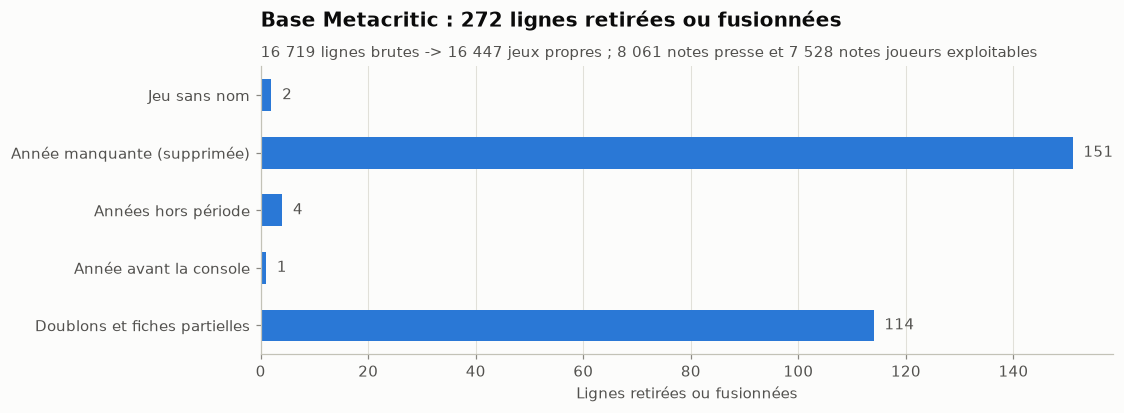

In [8]:
fig, ax = plt.subplots(figsize=(10, 3.4))
etapes = pd.DataFrame(journal).query("Écart != 0")
etiquettes = etapes["Étape"].str.replace(r"^\d\. ", "", regex=True)
ax.barh(etiquettes, -etapes["Écart"], color=C.PALETTE[0], height=0.55)
for y, v in enumerate(-etapes["Écart"]):
    ax.text(v + 2, y, f"{v}", va="center", color=C.ENCRE_2)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("Lignes retirées ou fusionnées")
viz.titre(ax, f"Base Metacritic : {len(raw) - len(df)} lignes retirées ou fusionnées",
          f"{viz.fr(len(raw), 0)} lignes brutes -> {viz.fr(len(df), 0)} jeux propres ; "
          f"{viz.fr(df['Critic_Score'].notna().sum(), 0)} notes presse et {viz.fr(df['User_Score'].notna().sum(), 0)} notes joueurs exploitables")
viz.sauver(fig, "25_bdd2_nettoyage")
plt.show()

**Lecture.** Les deux postes principaux sont les années impossibles à dater (151 lignes) et les doublons fusionnés (114 fiches). Ce sont **exactement les mêmes ordres de grandeur que dans la Partie I** (153 et 114) : les deux bases partagent le même scraping VGChartz, et le fait que les mêmes règles donnent les mêmes chiffres **valide** le nettoyage de la base 1.

**Bilan de la partie IV.1.**

| Problème | Traitement |
|---|---|
| 2 jeux sans nom ni genre | supprimés |
| 2 425 `User_Score` = `tbd` | -> manquants, colonne convertie en nombre |
| 51 % de notes presse manquantes | **non imputées** (biais de couverture documenté) |
| 255 éditeurs, 6 621 développeurs inconnus | modalité `Inconnu` |
| Classification ESRB vide, `RP`, `K-A` | `Non classé` ; `K-A` -> `E` |
| 269 années manquantes | 118 imputées, 151 supprimées |
| 4 sorties après 2016, 6 avant la console | 5 corrigées, 5 supprimées |
| 149 fiches `(... sales)` + doublons | 114 fiches fusionnées |
| Homonymes (remake / original) | note retirée sur 6 lignes |
| Échelles différentes (/100 et /10) | `User_Score_100`, écart presse - joueurs |
| Notes sur très peu d'avis | signalées : `Note_Presse_Fiable` (>= 5 critiques), `Note_Joueurs_Fiable` (>= 10 votes) |

Le fichier propre (`BDD_states/video_games_ratings_clean.csv`) compte **16 447 jeux** et **22 colonnes**, sans aucun doublon.

---
# Partie IV.2 : Analyse exploratoire des notes

## 1. Statistiques descriptives

In [9]:
notes = df[df["Critic_Score"].notna()]
print(f"Jeux avec une note presse : {len(notes):,} ({len(notes) / len(df):.0%}), soit {notes['Name'].nunique():,} titres distincts".replace(",", " "))
print(f"Jeux avec une note joueurs : {df['User_Score'].notna().sum():,} | avec les deux : {df['Ecart_Presse_Joueurs'].notna().sum():,}".replace(",", " "))
df[["Critic_Score", "Critic_Count", "User_Score_100", "User_Count", "Ecart_Presse_Joueurs"]].describe().T.round(1)

Jeux avec une note presse : 8 061 (49%)  soit 5 032 titres distincts
Jeux avec une note joueurs : 7 528 | avec les deux : 6 957


,count,mean,std,min,25%,50%,75%,max
Critic_Score,8061.0,68.988339,13.921541,13.0,60.0,71.0,79.0,98.0
Critic_Count,8061.0,26.378117,18.987986,3.0,12.0,21.0,36.0,113.0
User_Score_100,7528.0,71.244554,14.981139,0.0,64.0,75.0,82.0,97.0
User_Count,7528.0,162.384033,562.059895,4.0,10.0,24.0,81.0,10665.0
Ecart_Presse_Joueurs,6957.0,-1.568492,12.960864,-62.0,-9.0,-2.0,5.0,66.0


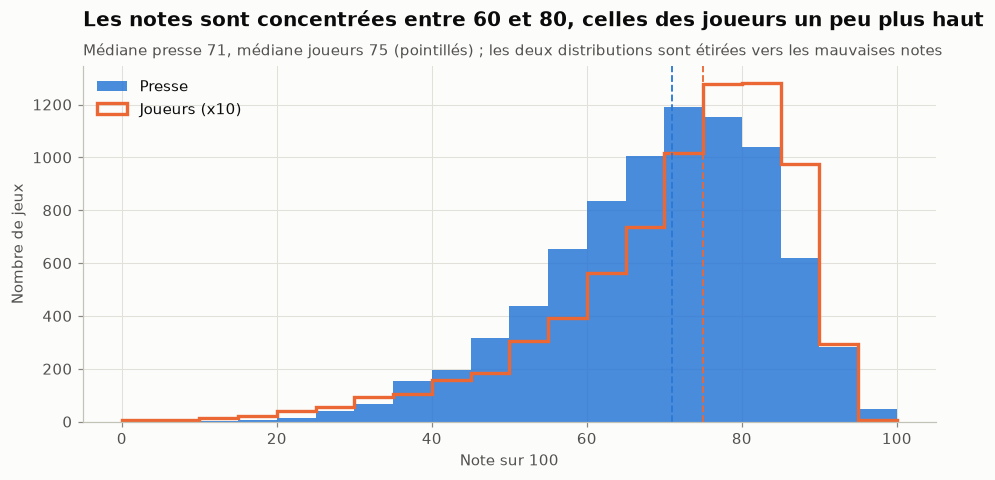

In [10]:
fig, ax = plt.subplots(figsize=(10, 4.2))
bins = np.arange(0, 101, 5)
ax.hist(df["Critic_Score"].dropna(), bins=bins, color=PRESSE, alpha=0.85, label="Presse")
ax.hist(df["User_Score_100"].dropna(), bins=bins, histtype="step", linewidth=2.2, color=JOUEURS, label="Joueurs (x10)")
for serie, couleur in [(df["Critic_Score"], PRESSE), (df["User_Score_100"], JOUEURS)]:
    ax.axvline(serie.median(), color=couleur, linestyle="--", linewidth=1.2)
ax.set_xlabel("Note sur 100")
ax.set_ylabel("Nombre de jeux")
ax.legend(loc="upper left")
viz.titre(ax, "Les notes sont concentrées entre 60 et 80, celles des joueurs un peu plus haut",
          f"Médiane presse {df['Critic_Score'].median():.0f}, médiane joueurs {df['User_Score_100'].median():.0f} (pointillés) ; "
          "les deux distributions sont étirées vers les mauvaises notes")
viz.sauver(fig, "26_bdd2_distribution_notes")
plt.show()

**Lecture.** La note presse moyenne est de **69/100** (médiane 71), la note joueurs de **71/100** (médiane 75). La moitié des jeux notés se situe entre 60 et 79 : les notes Metacritic ne s'utilisent pas sur toute l'échelle, et un 60 est déjà une note médiocre. Les deux distributions sont **asymétriques à gauche** : peu de jeux sous 50 (10 % des notes presse), mais quelques échecs notés autour de 20. Seul un jeu sur quatre atteint **80** ou plus, le seuil que le secteur considère comme celui d'un jeu « très bien reçu ».

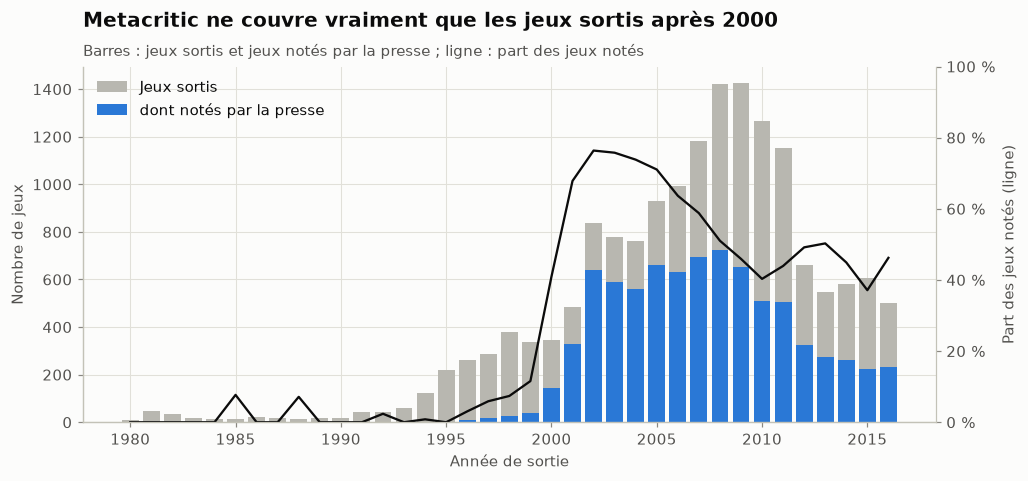

In [11]:
annees = df.groupby("Year").agg(Jeux=("Name", "size"), Notes=("Critic_Score", "count"))
annees["Couverture"] = annees["Notes"] / annees["Jeux"]

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.bar(annees.index, annees["Jeux"], color=C.GRIS, width=0.8, label="Jeux sortis")
ax.bar(annees.index, annees["Notes"], color=PRESSE, width=0.8, label="dont notés par la presse")
ax2 = ax.twinx()
ax2.plot(annees.index, annees["Couverture"], color=C.ENCRE, linewidth=1.5)
ax2.set_ylim(0, 1)
viz.format_pct(ax2)
ax2.grid(False)
ax2.spines["right"].set_visible(True)
ax2.set_ylabel("Part des jeux notés (ligne)")
ax.set_xlabel("Année de sortie")
ax.set_ylabel("Nombre de jeux")
ax.legend(loc="upper left")
viz.titre(ax, "Metacritic ne couvre vraiment que les jeux sortis après 2000",
          "Barres : jeux sortis et jeux notés par la presse ; ligne : part des jeux notés")
viz.sauver(fig, "27_bdd2_couverture_metacritic")
plt.show()

**Lecture.** Avant 2000, presque aucun jeu n'est noté (12 % au mieux en 1999). La couverture bondit à **76 % en 2002-2003**, puis redescend vers 40-50 % après 2008 : la production explose (plus de 1 400 jeux par an en 2008-2009, beaucoup de petits jeux DS et Wii) alors que la critique ne suit que les sorties les plus visibles. **Conséquence pour la suite** : toute conclusion tirée des notes vaut pour les jeux des années 2000-2016, et surtout pour les jeux assez visibles pour avoir été critiqués.

## 2. Top 10 des jeux les mieux notés

In [12]:
fiables = notes[notes["Note_Presse_Fiable"]]
# Un titre sort sur plusieurs plateformes : on garde sa meilleure version pour ne pas répéter GTA IV deux fois.
top = (fiables.sort_values(["Critic_Score", "Critic_Count"], ascending=False)
              .drop_duplicates("Name").head(10))
top[["Name", "Platform", "Year", "Critic_Score", "Critic_Count", "User_Score_100", "Developer_Main"]]

,Name,Platform,Year,Critic_Score,Critic_Count,User_Score_100,Developer_Main
0,Grand Theft Auto IV,X360,2008,98.0,86,79.0,Rockstar North
2,SoulCalibur,DC,1999,98.0,24,88.0,Namco
3,Tony Hawk's Pro Skater 2,PS,2000,98.0,19,77.0,Neversoft Entertainment
13,Super Mario Galaxy 2,Wii,2010,97.0,87,91.0,Nintendo EAD Tokyo
12,Super Mario Galaxy,Wii,2007,97.0,73,89.0,Nintendo
10,Metroid Prime,GC,2002,97.0,70,93.0,Retro Studios
9,Halo: Combat Evolved,XB,2001,97.0,68,86.0,Bungie Software
7,Grand Theft Auto V,PS4,2014,97.0,66,83.0,Rockstar North
4,Grand Theft Auto III,PS2,2001,97.0,56,85.0,DMA Design
14,Tony Hawk's Pro Skater 3,PS2,2001,97.0,34,75.0,Neversoft Entertainment


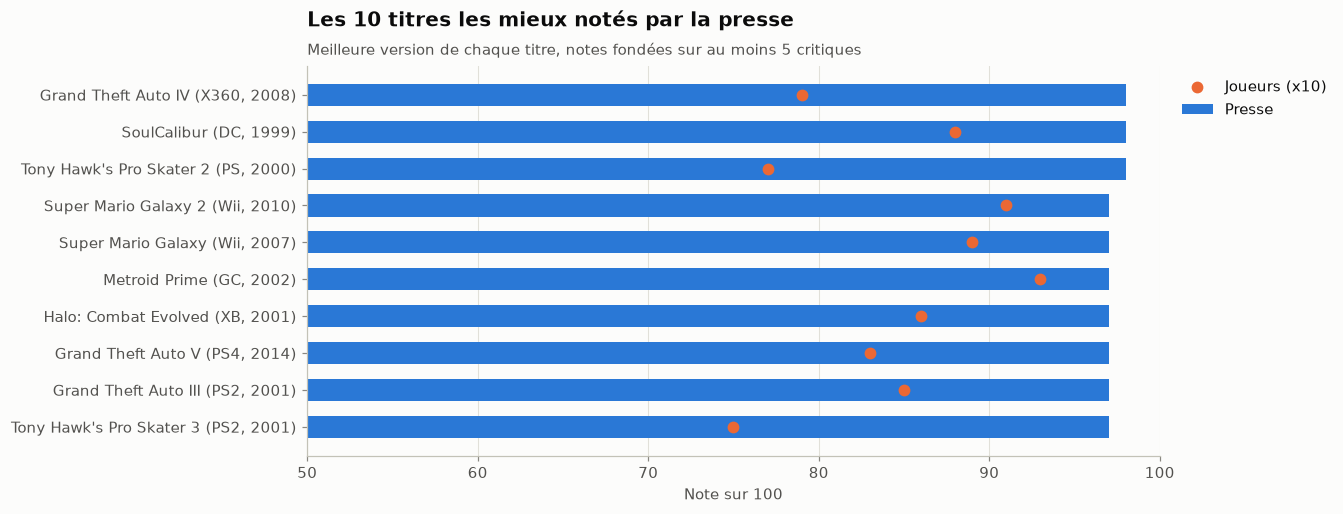

In [13]:
fig, ax = plt.subplots(figsize=(10, 4.6))
y = np.arange(len(top))
ax.barh(y, top["Critic_Score"], color=PRESSE, height=0.6, label="Presse")
ax.scatter(top["User_Score_100"], y, color=JOUEURS, zorder=3, s=45, label="Joueurs (x10)")
ax.set_yticks(y, [f"{n} ({p}, {a})" for n, p, a in zip(top["Name"], top["Platform"], top["Year"])])
ax.invert_yaxis()
ax.set_xlim(50, 100)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Note sur 100")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
viz.titre(ax, "Les 10 titres les mieux notés par la presse",
          f"Meilleure version de chaque titre, notes fondées sur au moins {SEUIL_CRITIQUES} critiques")
viz.sauver(fig, "28_bdd2_top10_notes")
plt.show()

**Lecture.** Le haut du classement est dominé par des **franchises de très gros éditeurs** : Rockstar (*GTA IV*, *GTA III*, *GTA V*), Nintendo (*Super Mario Galaxy*, *Metroid Prime*), Microsoft (*Halo*). Les joueurs sont presque toujours **moins généreux que la presse** sur ces titres : *GTA IV* a 98 chez les critiques mais 79 chez les joueurs. C'est la première trace d'un écart systématique entre les deux publics, étudié en section 5.

## 3. Tendances par année

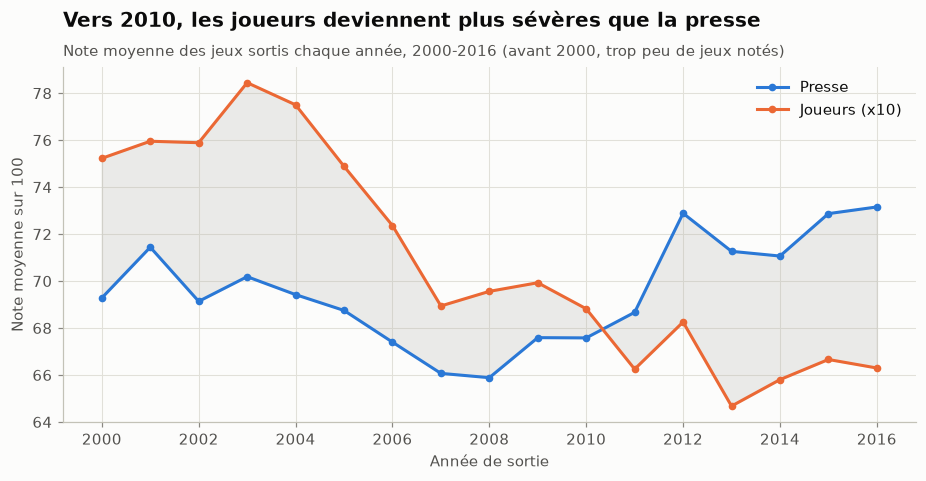

In [14]:
par_an = df[df["Year"] >= 2000].groupby("Year")[["Critic_Score", "User_Score_100"]].mean()

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(par_an.index, par_an["Critic_Score"], color=PRESSE, marker="o", markersize=4, label="Presse")
ax.plot(par_an.index, par_an["User_Score_100"], color=JOUEURS, marker="o", markersize=4, label="Joueurs (x10)")
ax.fill_between(par_an.index, par_an["Critic_Score"], par_an["User_Score_100"], color=C.GRIS, alpha=0.25)
ax.set_xlabel("Année de sortie")
ax.set_ylabel("Note moyenne sur 100")
ax.legend(loc="upper right")
viz.titre(ax, "Vers 2010, les joueurs deviennent plus sévères que la presse",
          "Note moyenne des jeux sortis chaque année, 2000-2016 (avant 2000, trop peu de jeux notés)")
viz.sauver(fig, "29_bdd2_notes_par_annee")
plt.show()

**Lecture.** Les deux courbes se **croisent vers 2010**. Avant, les joueurs notent plus haut que la presse, avec un écart de 6 à 7 points en 2003-2004. Après, c'est l'inverse : en 2016, la presse donne en moyenne 73 et les joueurs 66.

Deux explications, à présenter comme des hypothèses :

1. **Biais de sélection** : les joueurs qui notent aujourd'hui un jeu de 2003 sont surtout des fans nostalgiques, alors que les jeux récents sont notés à chaud, par tout le monde.
2. **« Review bombing »** : à partir des années 2010, des campagnes de joueurs mécontents (prix, contenu payant, DRM) font chuter les notes de certains très gros titres (voir section 5).

La note presse, elle, **remonte** après 2010 (de 66 à 73) : la critique se concentre sur moins de jeux, et sur de plus gros.

## 4. Genres, plateformes, éditeurs et classification d'âge

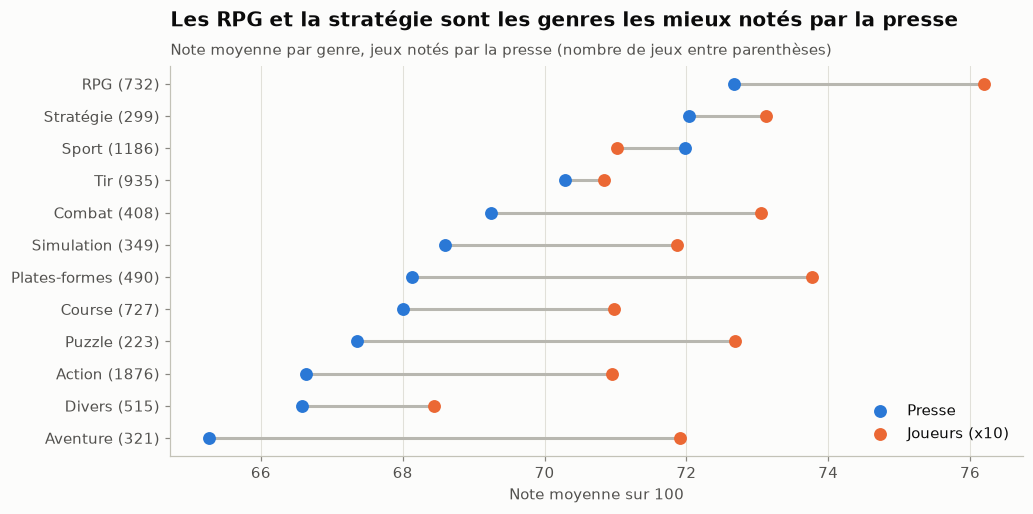

In [15]:
genres = notes.groupby("Genre").agg(Jeux=("Name", "size"), Presse=("Critic_Score", "mean"),
                                     Joueurs=("User_Score_100", "mean")).sort_values("Presse")
genres.index = genres.index.map(C.GENRES_FR)

fig, ax = plt.subplots(figsize=(10, 4.6))
y = np.arange(len(genres))
ax.hlines(y, genres["Presse"], genres["Joueurs"], color=C.GRIS, linewidth=2)
ax.scatter(genres["Presse"], y, color=PRESSE, s=55, zorder=3, label="Presse")
ax.scatter(genres["Joueurs"], y, color=JOUEURS, s=55, zorder=3, label="Joueurs (x10)")
ax.set_yticks(y, [f"{g} ({n})" for g, n in zip(genres.index, genres["Jeux"])])
ax.grid(axis="y", visible=False)
ax.set_xlabel("Note moyenne sur 100")
ax.legend(loc="lower right")
viz.titre(ax, "Les RPG et la stratégie sont les genres les mieux notés par la presse",
          "Note moyenne par genre, jeux notés par la presse (nombre de jeux entre parenthèses)")
viz.sauver(fig, "30_bdd2_notes_genres")
plt.show()

**Lecture.** Les écarts entre genres sont **modérés** (7 points entre le premier et le dernier), mais réguliers. Les **RPG** (72,7), la **stratégie** et le **sport** (72,0) sont les mieux notés par la presse ; l'**aventure** (65,3), l'**action** et les jeux **divers** (66,6) ferment la marche. L'action est pourtant le genre le plus représenté (1 876 jeux notés) : beaucoup de jeux, donc beaucoup de jeux moyens, comme les adaptations de films. Les joueurs notent presque tous les genres plus haut que la presse, **sauf le sport** (3 points de moins que la presse) : les éditions annuelles de *FIFA* ou de *Madden* sont bien accueillies par la critique mais lassent les joueurs.

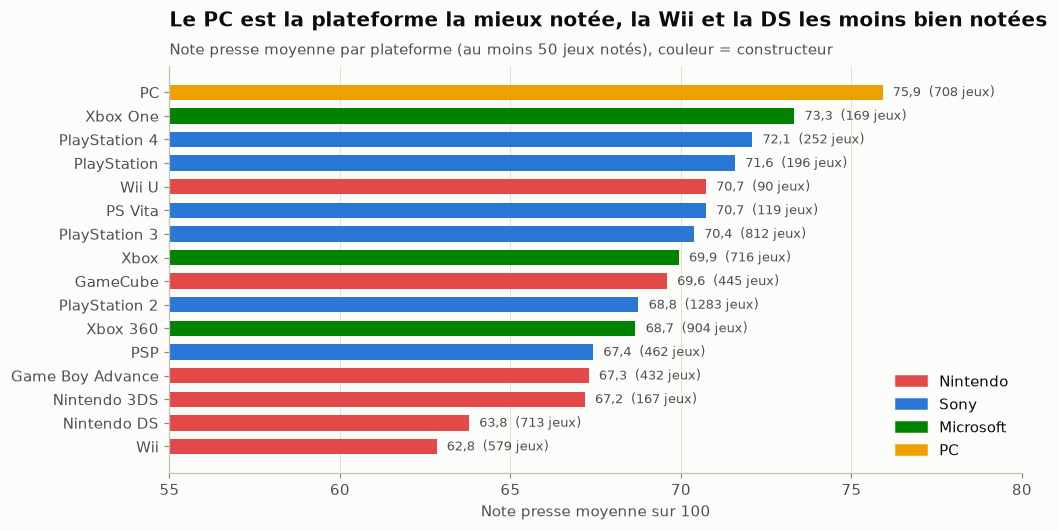

In [16]:
plat = (notes.groupby(["Platform", "Manufacturer"]).agg(Jeux=("Name", "size"), Presse=("Critic_Score", "mean"))
             .reset_index().query("Jeux >= 50").sort_values("Presse"))

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.barh(plat["Platform"].map(lambda p: C.PLATEFORMES[p][0]), plat["Presse"],
        color=plat["Manufacturer"].map(C.COULEURS_CONSTRUCTEUR), height=0.65)
for y, (v, n) in enumerate(zip(plat["Presse"], plat["Jeux"])):
    ax.text(v + 0.3, y, f"{viz.fr(v)}  ({n} jeux)", va="center", fontsize=8.5, color=C.ENCRE_2)
ax.set_xlim(55, 80)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Note presse moyenne sur 100")
constructeurs = [m for m in C.ORDRE_CONSTRUCTEURS if m in set(plat["Manufacturer"])]
ax.legend(handles=[Patch(color=C.COULEURS_CONSTRUCTEUR[m], label=m) for m in constructeurs], loc="lower right")
viz.titre(ax, "Le PC est la plateforme la mieux notée, la Wii et la DS les moins bien notées",
          "Note presse moyenne par plateforme (au moins 50 jeux notés), couleur = constructeur")
viz.sauver(fig, "31_bdd2_notes_plateformes")
plt.show()

**Lecture.** Le **PC** arrive en tête (75,9), suivi des consoles récentes **Xbox One** et **PS4** (environ 72-73). Les deux consoles Nintendo grand public, la **Wii** (62,8) et la **DS** (63,8), ferment la marche alors que ce sont les deux plateformes qui se sont le plus vendues de la base. Ce n'est pas que Nintendo fait de mauvais jeux (*Super Mario Galaxy* est dans le top 10) : ces consoles ont attiré un très grand nombre de **petits jeux à bas prix** (jeux familiaux, licences, *party games*) que la critique a mal notés. C'est le premier indice que **les notes et les ventes ne racontent pas la même histoire**, un point vérifié en Partie V.

La Dreamcast (87,4) n'apparaît pas car elle n'a que 14 jeux notés : sa moyenne n'est pas représentative.

In [17]:
editeurs = (notes.groupby("Publisher").agg(Jeux=("Name", "size"), Presse=("Critic_Score", "mean"),
                                           Part_80=("Critic_Score", lambda s: (s >= 80).mean()))
                 .query("Jeux >= 50").sort_values("Presse", ascending=False))
display(editeurs.head(10).round(2))
display(editeurs.tail(5).round(2))

,Jeux,Presse,Part_80
Publisher,,,
Microsoft Game Studios,147,76.11,0.47
Nintendo,309,75.49,0.41
Take-Two Interactive,294,75.01,0.45
Electronic Arts,1021,74.39,0.40
Square Enix,139,74.31,0.35
Sony Computer Entertainment,364,74.16,0.36
Bethesda Softworks,52,72.02,0.38
Capcom,214,71.60,0.27
Codemasters,122,71.06,0.34


,Jeux,Presse,Part_80
Publisher,,,
Rising Star Games,63,65.65,0.13
Tecmo Koei,145,65.57,0.09
Disney Interactive Studios,102,64.42,0.04
505 Games,95,61.93,0.13
Deep Silver,84,61.61,0.10


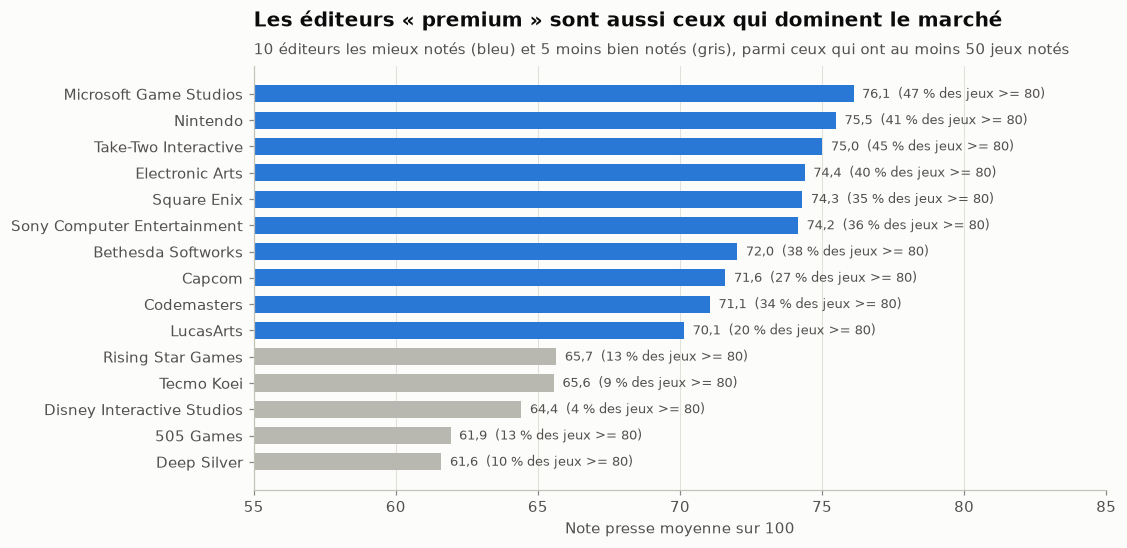

In [18]:
sel = pd.concat([editeurs.head(10), editeurs.tail(5)]).sort_values("Presse")
fig, ax = plt.subplots(figsize=(10, 5))
couleurs = [PRESSE if e in editeurs.head(10).index else C.GRIS for e in sel.index]
ax.barh(sel.index, sel["Presse"], color=couleurs, height=0.65)
for y, (v, p) in enumerate(zip(sel["Presse"], sel["Part_80"])):
    ax.text(v + 0.3, y, f"{viz.fr(v)}  ({viz.pct(p)} des jeux >= 80)", va="center", fontsize=8.5, color=C.ENCRE_2)
ax.set_xlim(55, 85)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Note presse moyenne sur 100")
viz.titre(ax, "Les éditeurs « premium » sont aussi ceux qui dominent le marché",
          "10 éditeurs les mieux notés (bleu) et 5 moins bien notés (gris), parmi ceux qui ont au moins 50 jeux notés")
viz.sauver(fig, "32_bdd2_notes_editeurs")
plt.show()

**Lecture.** Parmi les éditeurs qui ont au moins 50 jeux notés, **Microsoft** (76,1), **Nintendo** (75,5), **Take-Two** (75,0) et **Electronic Arts** (74,4) obtiennent les meilleures moyennes : chez eux, 40 à 47 % des jeux dépassent 80. On retrouve les mêmes noms dans le top 10 du *Market Power Index* de la Partie II (Nintendo 1er, EA 2e, Sony 3e, Take-Two 6e, Microsoft 10e), ce qui suggère qu'**une partie de leur puissance commerciale repose sur la qualité perçue**. À l'autre bout, des éditeurs de jeux sous licence ou à petit budget (*Disney Interactive*, *505 Games*, *Deep Silver*) restent autour de 62-64. On teste en Partie V si la qualité change le classement MPI.

Côté **studios** (`Developer`), la note moyenne la plus haute, parmi ceux qui ont au moins 25 jeux notés, revient à EA DICE (*Battlefield*), Visual Concepts (*NBA 2K*) et Neversoft (*Tony Hawk*), autour de 81.

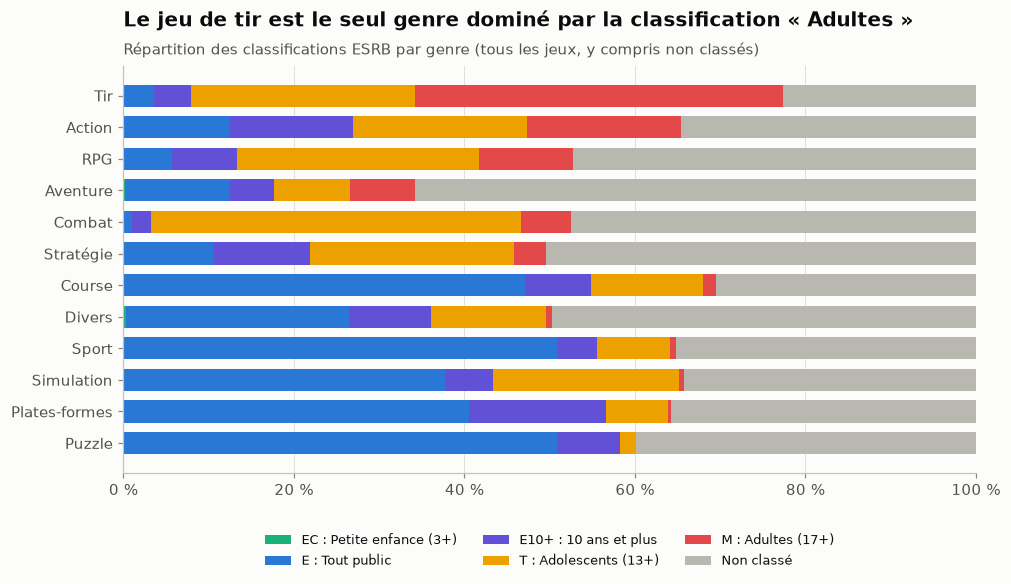

In [19]:
ordre_esrb = ["EC", "E", "E10+", "T", "M", "AO", "Non classé"]
esrb = pd.crosstab(df["Genre"].map(C.GENRES_FR), df["Rating"], normalize="index")[ordre_esrb[:-2] + ["Non classé"]]
esrb = esrb.sort_values("M")
couleurs_esrb = {"EC": C.PALETTE[2], "E": C.PALETTE[0], "E10+": C.PALETTE[6], "T": C.PALETTE[3],
                 "M": C.PALETTE[7], "Non classé": C.GRIS}

fig, ax = plt.subplots(figsize=(10, 4.8))
gauche = np.zeros(len(esrb))
for cat in esrb.columns:
    ax.barh(esrb.index, esrb[cat], left=gauche, color=couleurs_esrb[cat], height=0.7,
            label=cat if cat == "Non classé" else f"{cat} : {C.ESRB_LABELS[cat]}")
    gauche += esrb[cat].to_numpy()
viz.format_pct(ax, "x")
ax.set_xlim(0, 1)
ax.grid(axis="y", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, fontsize=8.5)
viz.titre(ax, "Le jeu de tir est le seul genre dominé par la classification « Adultes »",
          "Répartition des classifications ESRB par genre (tous les jeux, y compris non classés)")
viz.sauver(fig, "33_bdd2_classification_esrb")
plt.show()

**Lecture.** 40 % des jeux n'ont pas de classification, pour la même raison que les notes : l'ESRB, organisme nord-américain, est récent (1994) et la base ne la renseigne pas pour les jeux anciens ou uniquement japonais. Parmi les jeux classés, la répartition suit logiquement le contenu : **43 % des jeux de tir** sont classés *M* (17 ans et plus), alors que le **sport**, le **puzzle** et la **course** sont classés *E* (tout public) à environ 50 %. Les jeux de **combat** sont surtout *T* (43 %). Un seul jeu de la base est classé *AO* (adultes uniquement), une classification que les constructeurs refusent sur leurs consoles et qui est donc presque introuvable en pratique.

## 5. Presse contre joueurs

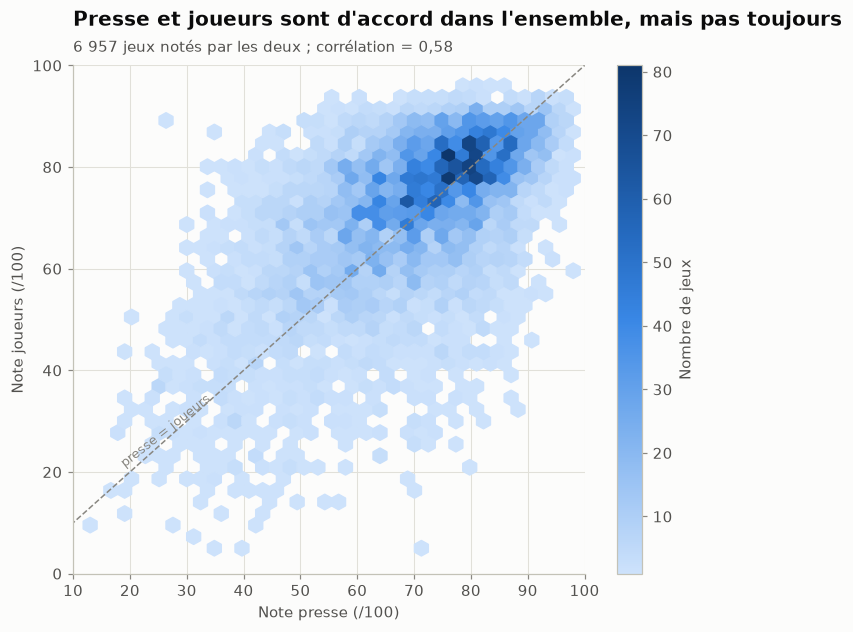

In [20]:
deux = df.dropna(subset=["Critic_Score", "User_Score_100"])
corr = deux["Critic_Score"].corr(deux["User_Score_100"])

fig, ax = plt.subplots(figsize=(7.5, 6))
hb = ax.hexbin(deux["Critic_Score"], deux["User_Score_100"], gridsize=35, cmap=viz.CMAP_SEQ, mincnt=1)
ax.plot([0, 100], [0, 100], color=C.ENCRE_MUTED, linestyle="--", linewidth=1)
ax.text(18, 21, "presse = joueurs", color=C.ENCRE_MUTED, fontsize=8.5, rotation=38)
fig.colorbar(hb, ax=ax, label="Nombre de jeux")
ax.set_xlim(10, 100)
ax.set_ylim(0, 100)
ax.set_xlabel("Note presse (/100)")
ax.set_ylabel("Note joueurs (/100)")
viz.titre(ax, "Presse et joueurs sont d'accord dans l'ensemble, mais pas toujours",
          f"{viz.fr(len(deux), 0)} jeux notés par les deux ; corrélation = {viz.fr(corr, 2)}")
viz.sauver(fig, "34_bdd2_presse_vs_joueurs")
plt.show()

In [21]:
fiables2 = deux[deux["Note_Presse_Fiable"] & deux["Note_Joueurs_Fiable"]]
cols = ["Name", "Platform", "Year", "Critic_Score", "User_Score_100", "User_Count"]
print("La presse beaucoup plus enthousiaste que les joueurs :")
display(fiables2.sort_values("Ecart_Presse_Joueurs", ascending=False).head(5)[cols])
print("Les joueurs beaucoup plus enthousiastes que la presse :")
display(fiables2.sort_values("Ecart_Presse_Joueurs").head(5)[cols])

La presse beaucoup plus enthousiaste que les joueurs :


,Name,Platform,Year,Critic_Score,User_Score_100,User_Count
3807,Thrillville: Off the Rails,PSP,2007,72.0,6.0,24
1784,Company of Heroes 2,PC,2013,80.0,21.0,6157
451,Call of Duty: Modern Warfare 3,PS3,2011,88.0,32.0,5234
450,Call of Duty: Modern Warfare 3,X360,2011,88.0,34.0,8713
2240,Call of Duty: Modern Warfare 3,PC,2011,78.0,25.0,5664


Les joueurs beaucoup plus enthousiastes que la presse :


,Name,Platform,Year,Critic_Score,User_Score_100,User_Count
8021,Shrek Swamp Kart Speedway,GBA,2002,27.0,89.0,19
7958,Shrek Super Party,XB,2002,33.0,80.0,11
7946,BeyBlade VForce: Super Tournament Battle,GC,2002,33.0,75.0,18
7840,Pure Futbol,X360,2010,38.0,79.0,29
7462,Predator: Concrete Jungle,PS2,2005,47.0,88.0,76


**Lecture.** La corrélation entre les deux notes est de **0,58** : un jeu bien noté par la presse l'est en général par les joueurs, mais la relation est loin d'être parfaite. Les points sous la diagonale sont les jeux que les joueurs ont moins aimés que la presse.

Les écarts les plus forts racontent deux histoires différentes :

- **Les joueurs sanctionnent des jeux à gros budget** : *Call of Duty: Modern Warfare 3* (88 pour la presse, 32 à 34 pour les joueurs, sur plus de 5 000 votes) et *Company of Heroes 2* (80 contre 21) sont des cas typiques de **« review bombing »**, des campagnes de protestation menées dans les notes.
- **Les joueurs défendent des jeux pour enfants que la critique a descendus** : *Shrek Swamp Kart Speedway* (27 pour la presse, 89 pour les joueurs), mais sur une vingtaine de votes seulement, d'où l'intérêt de l'indicateur de fiabilité.

**Ce qu'il faut retenir pour la suite.** La note **presse** est la plus fiable pour mesurer la qualité : plus d'avis par jeu, une échelle stable, peu de campagnes. C'est elle qu'on utilisera en priorité pour le croisement avec les ventes (Partie V).

---
# Synthèse de la Partie IV

1. **Une base complémentaire, mais partielle.** Metacritic apporte la qualité perçue (presse et joueurs), le studio et la classification d'âge, mais seulement pour **49 % des jeux**, quasiment tous sortis après 2000.
2. **Un nettoyage qui confirme la Partie I** : mêmes défauts, mêmes règles, mêmes ordres de grandeur. On y ajoute deux problèmes propres à la base : les `tbd` et les **fausses correspondances** du scraping (remakes notés comme l'original).
3. **La qualité perçue varie selon le genre et la plateforme** : RPG, stratégie et PC en tête, Wii et DS en bas du classement malgré leurs ventes record.
4. **Les éditeurs dominants sont aussi les mieux notés** (Microsoft, Nintendo, Take-Two, EA).
5. **Presse et joueurs divergent depuis 2010** : les joueurs, autrefois plus généreux, sont devenus plus sévères que la critique.

**Partie V** : relier cette base aux ventes de `vgsales_clean.csv` pour mesurer si une bonne note fait vendre, et si elle change le classement des éditeurs.

---
# Partie V : Relier les notes aux ventes

## 1. Méthode de jointure

**Clé.** On relie les deux bases sur **nom normalisé + plateforme + année**. La plateforme est indispensable (un même jeu n'a pas la même note sur PS3 et sur Wii), et l'année l'est aussi (elle distingue *Need for Speed: Most Wanted* 2005 de son remake de 2012).

**Normalisation des noms.** Les noms ne sont jamais écrits exactement pareil d'une source à l'autre. On réutilise la fonction `cle_jeu` de la Partie I : minuscules, suppression de toute ponctuation et des espaces, suppression des suffixes `(JP sales)`. Ainsi, `"WWE SmackDown! vs. RAW 2006"` et `"wwe Smackdown vs. Raw 2006"` donnent la même clé.

**Type de jointure.** Jointure **à gauche** depuis `vgsales_clean.csv` : on garde tous les jeux de l'analyse des ventes, et on y ajoute les notes quand elles existent. `validate="one_to_one"` garantit qu'aucun jeu n'est dupliqué par la jointure.

In [22]:
from modules import indicators as I
from modules import jointure as J
from modules.cleaning import charger_donnees_propres

ventes = charger_donnees_propres()           # vgsales_clean, mêmes règles que la Partie I
joint = J.joindre(ventes, df)
joint.to_csv(C.JOINTURE_FILE, index=False)
print("Lignes avant / après jointure :", len(ventes), "/", len(joint))
exemples = pd.DataFrame({"Nom": ["WWE SmackDown! vs. RAW 2006", "Pokemon Red/Pokemon Blue", "Naruto: Ultimate Ninja (JP sales)"]})
exemples["Clé normalisée"] = cle_jeu(exemples["Nom"])
exemples

Lignes avant / après jointure : 16326 / 16326


,Nom,Clé normalisée
0,WWE SmackDown! vs. RAW 2006,wwesmackdownvsraw2006
1,Pokemon Red/Pokemon Blue,pokemonredpokemonblue
2,Naruto: Ultimate Ninja (JP sales),narutoultimateninja


## 2. Taux de correspondance

In [23]:
bilan = J.bilan_jointure(joint, df)
bilan.style.format({"Jeux": "{:,.0f}", "Ventes (M)": "{:,.1f}", "Part des jeux": "{:.1%}", "Part des ventes": "{:.2%}"}, na_rep="")

,Jeux,Ventes (M),Part des jeux,Part des ventes
Jeux de vgsales_clean,"16,326","8,861.4",100.0%,100.00%
reliés à la base Metacritic,"16,282","8,860.9",99.7%,99.99%
dont avec une note presse,"7,974","5,580.7",48.8%,62.98%
non reliés,44,0.6,0.3%,0.01%
Jeux Metacritic absents de vgsales_clean,165,,,


**Lecture.** La jointure est presque parfaite : **99,7 % des jeux** de `vgsales_clean` (16 282 sur 16 326) retrouvent leur fiche Metacritic, et ils représentent **99,99 % des ventes**. Ce n'est pas un hasard : les deux bases viennent du même scraping VGChartz. Un taux aussi élevé serait suspect entre deux sources indépendantes ; ici, il est attendu.

**Mais relier n'est pas noter.** Une fois reliés, seuls **49 % des jeux ont une note presse**. Ils représentent cependant **63 % des ventes** : les jeux notés sont en moyenne de plus gros vendeurs. C'est ce biais qu'il faut mesurer.

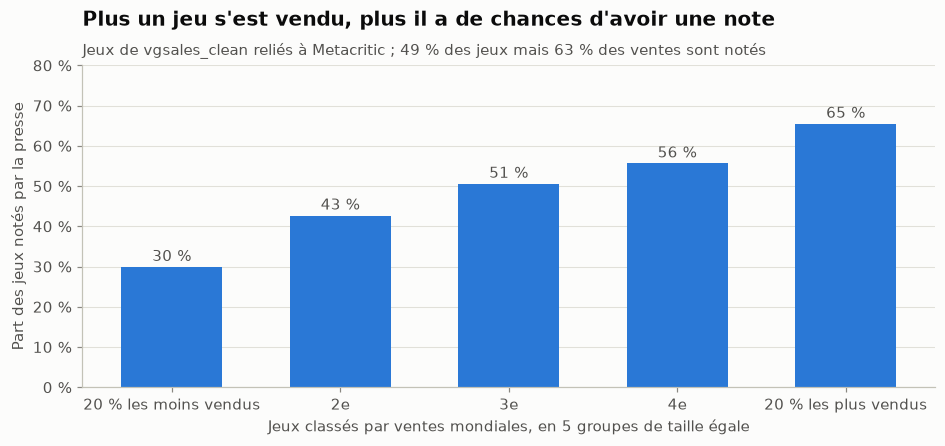

In [24]:
joint["Tranche_ventes"] = pd.qcut(joint["Global_Sales"].rank(method="first"), 5,
                                  labels=["20 % les moins vendus", "2e", "3e", "4e", "20 % les plus vendus"])
couv = joint.groupby("Tranche_ventes", observed=True).agg(Jeux=("Name", "size"), Couverture=("Note_Presse", "mean"),
                                                           Ventes_min=("Global_Sales", "min"), Ventes_max=("Global_Sales", "max"))

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(couv.index.astype(str), couv["Couverture"], color=PRESSE, width=0.6)
for x, v in enumerate(couv["Couverture"]):
    ax.text(x, v + 0.015, viz.pct(v), ha="center", color=C.ENCRE_2)
ax.set_ylim(0, 0.8)
viz.format_pct(ax)
ax.grid(axis="x", visible=False)
ax.set_xlabel("Jeux classés par ventes mondiales, en 5 groupes de taille égale")
ax.set_ylabel("Part des jeux notés par la presse")
viz.titre(ax, "Plus un jeu s'est vendu, plus il a de chances d'avoir une note",
          f"Jeux de vgsales_clean reliés à Metacritic ; {viz.pct(joint['Note_Presse'].mean())} des jeux mais "
          f"{viz.pct(joint.loc[joint['Note_Presse'], 'Global_Sales'].sum() / joint['Global_Sales'].sum())} des ventes sont notés")
viz.sauver(fig, "35_jointure_couverture_ventes")
plt.show()

**Lecture. Le biais est net** : 30 % des jeux les moins vendus ont une note presse, contre 65 % des 20 % les plus vendus. Les critiques testent en priorité les jeux attendus, donc ceux qui ont le plus de chances de bien se vendre. **Conséquence** : les analyses croisées ci-dessous décrivent surtout les jeux visibles. Elles sous-représentent les petits jeux, qui sont pourtant ceux qui se vendent le moins et que la critique a souvent mal notés. Le lien entre note et ventes est donc probablement **sous-estimé** plutôt que surestimé.

## 3. Vérifications à la main

In [25]:
# a) Jeux de vgsales_clean sans partenaire
print(f"Jeux non reliés : {(~joint['Relie']).sum()}, pour {joint.loc[~joint['Relie'], 'Global_Sales'].sum():.2f} M de ventes")
display(joint.loc[~joint["Relie"], ["Name", "Platform", "Year", "Publisher", "Global_Sales"]].head(8))

# b) Jeux Metacritic sans partenaire
cles_ventes = set(zip(cle_jeu(ventes["Name"].astype(str)), ventes["Platform"].astype(str), ventes["Year"]))
seuls = df[[c not in cles_ventes for c in zip(cle_jeu(df["Name"]), df["Platform"], df["Year"])]]
print("Jeux Metacritic absents de vgsales_clean, par année :", seuls["Year"].value_counts().sort_index().to_dict())

Jeux non reliés : 44, pour 0.56 M de ventes


,Name,Platform,Year,Publisher,Global_Sales
14601,The Peanuts Movie: Snoopy's Grand Adventure,X360,2015,Activision,0.03
14743,Barbie and Her Sisters Puppy Rescue,PS3,2015,Namco Bandai Games,0.02
14790,Canimal Triple,PSV,2014,Warner Bros. Interactive Entertainment,0.02
14821,Clue / Mouse Trap / Perfection / Aggravation,DS,2006,Inconnu,0.02
15068,Invizimals: The Resistance,PSV,2014,Sony Computer Entertainment,0.02
15076,Jewel Link: Galactic Quest,DS,2012,Avanquest Software,0.02
15247,NHL 16,X360,2015,Electronic Arts,0.02
15356,Puzzle Chronicles,DS,2010,Konami Digital Entertainment,0.02


Jeux Metacritic absents de vgsales_clean, par année : {2000: 1, 2014: 5, 2015: 1, 2016: 158}


In [26]:
# c) Les deux relevés de ventes sont-ils identiques ? (ventes brutes de la base 2, avant qu'on les écarte)
brut2 = raw.dropna(subset=["Name"]).assign(_cle=lambda d: cle_jeu(d["Name"]))
brut2 = brut2.groupby(["_cle", "Platform", "Year_of_Release"])["Global_Sales"].sum().rename("Ventes_base2")
comp = ventes.assign(_cle=cle_jeu(ventes["Name"].astype(str))).join(brut2, on=["_cle", "Platform", "Year"], how="inner")
ecart = (comp["Global_Sales"] - comp["Ventes_base2"]).abs()
print(f"Ventes identiques au centième : {(ecart < 0.005).mean():.0%} des jeux reliés ; écart > 0,1 M : {(ecart > 0.1).sum()} jeux")
comp.loc[ecart > 0.1, ["Name", "Platform", "Year", "Global_Sales", "Ventes_base2"]].head(6)

Ventes identiques au centième : 75% des jeux reliés ; écart > 0,1 M : 186 jeux


,Name,Platform,Year,Global_Sales,Ventes_base2
0,Wii Sports,Wii,2006,82.74,82.53
2,Mario Kart Wii,Wii,2008,35.82,35.52
3,Wii Sports Resort,Wii,2009,33.00,32.77
6,New Super Mario Bros.,DS,2006,30.01,29.80
8,New Super Mario Bros. Wii,Wii,2009,28.62,28.32
11,Mario Kart DS,DS,2005,23.42,23.21


In [27]:
# d) Contrôle visuel d'un échantillon aléatoire de jeux reliés et notés
joint.loc[joint["Note_Presse"], ["Name", "Platform", "Year", "Publisher", "Global_Sales", "Critic_Score", "Developer"]].sample(8, random_state=1)

,Name,Platform,Year,Publisher,Global_Sales,Critic_Score,Developer
6553,Amped 2,XB,2003,Microsoft Game Studios,0.25,80.0,Indie Built
2444,Harvest Moon: Tree of Tranquility,Wii,2007,Rising Star Games,0.84,65.0,Marvelous Entertainment
14895,Disney's Meet the Robinsons,DS,2007,Disney Interactive Studios,0.02,64.0,"Climax Group, Climax Studios"
11714,Fable: The Lost Chapters,PC,2005,Microsoft Game Studios,0.07,83.0,Lionhead Studios
4806,Rampage: Total Destruction,GC,2006,Midway Games,0.40,57.0,"Pipeworks Software, Inc."
8300,Spawn: Armageddon,XB,2003,Electronic Arts,0.17,57.0,Point of View
6269,Growlanser: Heritage of War,PS2,2006,Rising Star Games,0.27,60.0,Career Soft
147,Final Fantasy XII,PS2,2006,Square Enix,5.95,92.0,Square Enix


**Bilan des vérifications.**

- **Les 44 jeux non reliés** sont tous de très petits jeux (0,56 M de ventes au total, aucun au-dessus de 0,03 M). Ils ont probablement été retirés ou renommés sur VGChartz entre les deux relevés. Leur perte est négligeable.
- **Les 165 jeux présents seulement dans Metacritic** sont presque tous sortis **fin 2016** (*Battlefield 1*, *Titanfall 2*, *Dishonored 2*...) : le scraping Metacritic est plus récent de quelques semaines et contient des sorties que `vgsales.csv` n'avait pas encore.
- **Les ventes ne sont pas identiques** : 75 % des jeux reliés ont exactement les mêmes ventes, mais 186 diffèrent de plus de 0,1 M (*Wii Sports* : 82,74 M contre 82,53 M). Ce sont deux relevés de VGChartz faits à des dates différentes. Cela **confirme le choix de la Partie IV** : une seule source de vérité pour les ventes, sinon les chiffres de la présentation se contrediraient.
- **Pas de fausse jointure dans l'échantillon** : pour les jeux tirés au hasard, éditeur et studio sont cohérents avec le titre. Les homonymes connus (remakes) sont séparés par l'année, et les notes ambiguës ont été retirées en Partie IV.

## 4. Une bonne note fait-elle vendre ?

In [28]:
notes_v = joint[joint["Note_Presse"]].copy()
notes_v["Tranche_note"] = pd.cut(notes_v["Critic_Score"], [0, 50, 60, 70, 80, 90, 101], right=False,
                                 labels=["< 50", "50-59", "60-69", "70-79", "80-89", "90 et +"])
notes_v["Hit"] = notes_v["Global_Sales"] >= C.SEUIL_HIT
par_note = notes_v.groupby("Tranche_note", observed=True).agg(
    Jeux=("Name", "size"), Ventes_medianes=("Global_Sales", "median"),
    Ventes_moyennes=("Global_Sales", "mean"), Taux_hits=("Hit", "mean"))
par_note.round(3)

,Jeux,Ventes_medianes,Ventes_moyennes,Taux_hits
Tranche_note,,,,
< 50,788,0.12,0.236,0.038
50-59,1091,0.16,0.305,0.046
60-69,1816,0.18,0.373,0.075
70-79,2308,0.29,0.612,0.157
80-89,1642,0.60,1.238,0.347
90 et +,329,1.54,2.855,0.620


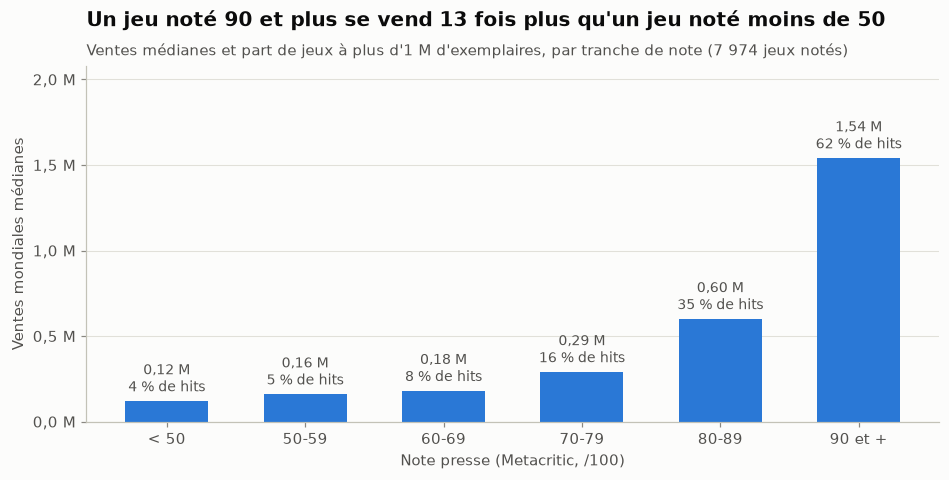

In [29]:
fig, ax = plt.subplots(figsize=(10, 4.2))
x = np.arange(len(par_note))
ax.bar(x, par_note["Ventes_medianes"], color=PRESSE, width=0.6)
for xi, (v, h) in enumerate(zip(par_note["Ventes_medianes"], par_note["Taux_hits"])):
    ax.text(xi, v + 0.03, f"{viz.fr(v, 2)} M\n{viz.pct(h)} de hits", ha="center", va="bottom", fontsize=9, color=C.ENCRE_2)
ax.set_xticks(x, par_note.index)
ax.set_ylim(0, par_note["Ventes_medianes"].max() * 1.35)
format_m = lambda v, _: viz.fr(v, 1) + " M"
ax.yaxis.set_major_formatter(plt.FuncFormatter(format_m))
ax.yaxis.set_major_locator(plt.MultipleLocator(0.5))
ax.grid(axis="x", visible=False)
ax.set_xlabel("Note presse (Metacritic, /100)")
ax.set_ylabel("Ventes mondiales médianes")
viz.titre(ax, "Un jeu noté 90 et plus se vend 13 fois plus qu'un jeu noté moins de 50",
          f"Ventes médianes et part de jeux à plus d'1 M d'exemplaires, par tranche de note ({viz.fr(len(notes_v), 0)} jeux notés)")
viz.sauver(fig, "36_jointure_ventes_par_note")
plt.show()

In [30]:
log_ventes = np.log10(notes_v["Global_Sales"])
# Comparer chaque jeu aux jeux de la même plateforme et de la même année neutralise l'effet "console à succès".
groupe = [notes_v["Platform"], notes_v["Year"]]
intra = (log_ventes - log_ventes.groupby(groupe).transform("mean")).corr(
    notes_v["Critic_Score"] - notes_v.groupby(groupe)["Critic_Score"].transform("mean"))
pd.Series({
    "Note presse": log_ventes.corr(notes_v["Critic_Score"]),
    "Note joueurs": log_ventes.corr(notes_v["User_Score_100"]),
    "Nombre de critiques (visibilité)": log_ventes.corr(notes_v["Critic_Count"]),
    "Note presse, à plateforme et année égales": intra,
}, name="Corrélation avec log(ventes)").round(2).to_frame()

,Corrélation avec log(ventes)
Note presse,0.38
Note joueurs,0.16
Nombre de critiques (visibilité),0.45
"Note presse, à plateforme et année égales",0.47


In [31]:
print("Corrélation note presse / log(ventes) par constructeur :")
display(notes_v.groupby("Manufacturer").apply(lambda g: np.log10(g["Global_Sales"]).corr(g["Critic_Score"])).round(2).to_frame("corrélation"))
print("Gros succès malgré une note médiocre (< 65) :")
display(notes_v[notes_v["Critic_Score"] < 65].nlargest(6, "Global_Sales")[["Name", "Platform", "Year", "Publisher", "Critic_Score", "Global_Sales"]])
part_80 = notes_v.loc[notes_v["Critic_Score"] >= 80, "Global_Sales"].sum() / notes_v["Global_Sales"].sum()
print(f"Les jeux notés 80 et plus : {(notes_v['Critic_Score'] >= 80).mean():.0%} des jeux notés, {part_80:.0%} de leurs ventes")

Corrélation note presse / log(ventes) par constructeur :


,corrélation
Manufacturer,
Microsoft,0.52
Nintendo,0.34
PC,0.36
Sega,0.35
Sony,0.49


Gros succès malgré une note médiocre (< 65) :


,Name,Platform,Year,Publisher,Critic_Score,Global_Sales
7,Wii Play,Wii,2006,Nintendo,58.0,29.02
15,Kinect Adventures!,X360,2010,Microsoft Game Studios,61.0,21.82
80,Mario Party 8,Wii,2007,Nintendo,62.0,8.42
102,Just Dance,Wii,2009,Ubisoft,49.0,7.27
223,Driver 2,PS,2000,Atari,62.0,4.73
247,Michael Jackson: The Experience,Wii,2010,Ubisoft,56.0,4.42


Les jeux notés 80 et plus : 25% des jeux notés, 53% de leurs ventes


**Lecture. Oui, la note est liée aux ventes, et fortement :**

- les ventes médianes passent de **0,12 M** pour un jeu noté moins de 50 à **1,54 M** pour un jeu noté 90 et plus, soit **13 fois plus** ;
- la part de hits (plus d'un million d'exemplaires) passe de **4 % à 62 %** ;
- les jeux notés 80 et plus ne font qu'**un quart des jeux notés** mais **plus de la moitié de leurs ventes** (53 %).

**Mais attention à la causalité.** Trois résultats invitent à la prudence :

1. **Le nombre de critiques prédit les ventes au moins aussi bien que la note** (corrélation 0,45 contre 0,38). Un jeu très critiqué est un jeu très attendu, avec un gros budget marketing : la note et les ventes peuvent toutes deux être la conséquence du budget, sans que l'une cause l'autre.
2. **À plateforme et année égales, le lien est même un peu plus fort** (0,47) : il ne s'explique donc pas par le succès de certaines consoles.
3. **Le public de Nintendo est le moins sensible aux notes** (corrélation 0,34, contre 0,49 à 0,52 chez Sony et Microsoft). Les plus gros contre-exemples sont des jeux familiaux de la Wii et de Kinect : *Wii Play* (58/100, **29 M** d'exemplaires), *Kinect Adventures!* (61/100, 22 M), *Just Dance* (49/100, 7 M). Ces jeux sont vendus avec la console ou à un public qui ne lit pas la presse spécialisée.

La **note joueurs** est beaucoup moins liée aux ventes (0,16) : elle est souvent donnée après coup, et elle est sensible aux campagnes.

## 5. La qualité change-t-elle le classement des éditeurs ?

On ajoute au *Market Power Index* de la Partie II une **6e composante, la qualité perçue** : la note presse moyenne de l'éditeur, **pondérée par les ventes** (un succès compte plus qu'un jeu confidentiel), calculée sur les notes fiables (au moins 5 critiques). Les 6 composantes sont normalisées de la même façon (min-max) et pèsent chacune 1/6.

**Règle de prudence.** Quand moins de 30 % des jeux d'un éditeur sont notés, ou qu'il a moins de 5 notes fiables, sa note moyenne n'est pas représentative. On lui attribue alors la **note médiane** des éditeurs, qui ne le favorise ni ne le pénalise. C'est le cas de 26 éditeurs sur 73, surtout des éditeurs **japonais** (Idea Factory, Banpresto, Hudson Soft...) que Metacritic, site américain, couvre mal.

In [32]:
mpi_avant = I.market_power_index(ventes)
mpi_apres = J.market_power_index_qualite(joint)
comparaison = mpi_apres[["rang", "MPI", "qualite_brute", "couverture", "qualite_representative"]].join(
    mpi_avant[["rang", "MPI"]].add_suffix("_avant"))
comparaison["gain_places"] = comparaison["rang_avant"] - comparaison["rang"]
print("Corrélation des rangs avant / après :", round(comparaison["rang"].corr(comparaison["rang_avant"]), 3))
print("Éditeurs communs aux deux top 10 :",
      len(set(comparaison.nsmallest(10, "rang").index) & set(comparaison.nsmallest(10, "rang_avant").index)))
comparaison.head(15).round(2)

Corrélation des rangs avant / après : 0.966


Éditeurs communs aux deux top 10 :

 9


,rang,MPI,qualite_brute,couverture,qualite_representative,rang_avant,MPI_avant,gain_places
Publisher,,,,,,,,
Nintendo,1,93.03,79.91,0.44,True,1,95.51,0
Electronic Arts,2,75.20,79.22,0.76,True,2,74.50,0
Sony Computer Entertainment,3,65.55,83.48,0.52,True,3,60.53,0
Activision,4,62.44,79.91,0.57,True,4,58.81,0
Take-Two Interactive,5,58.23,86.52,0.69,True,6,50.04,1
Bethesda Softworks,6,55.44,85.66,0.69,True,9,47.18,3
Microsoft Game Studios,7,53.69,81.97,0.77,True,10,47.15,3
Virgin Interactive,8,52.62,86.81,0.31,True,14,43.15,6
Ubisoft,9,51.58,75.59,0.61,True,8,48.20,-1


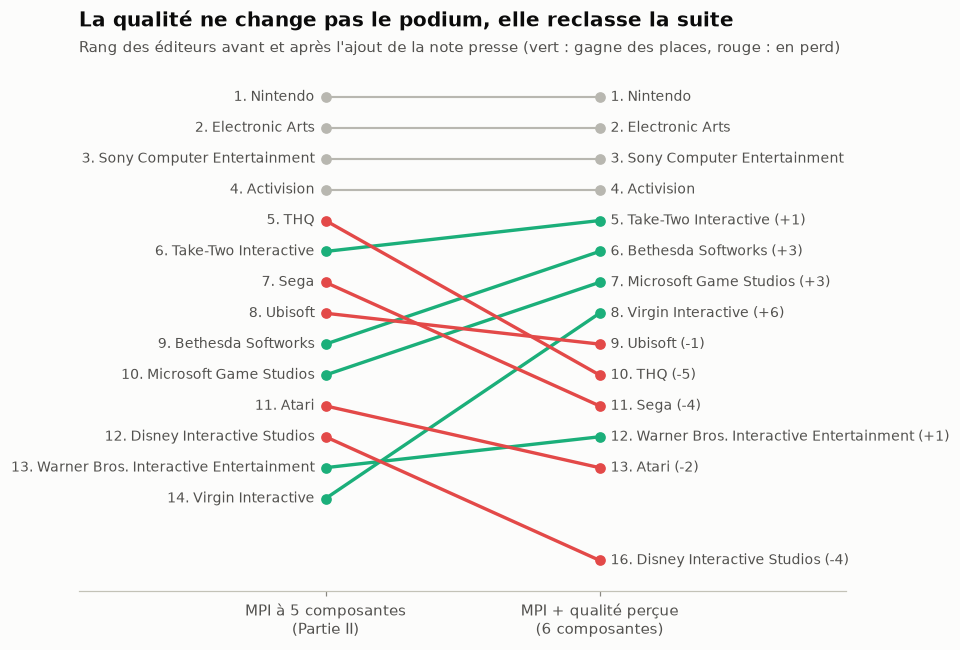

In [33]:
sel = comparaison[(comparaison["rang"] <= 12) | (comparaison["rang_avant"] <= 12)].copy()
fig, ax = plt.subplots(figsize=(9, 6.2))
pos_g = viz.repartir(sel["rang_avant"], 0.9)
pos_d = viz.repartir(sel["rang"], 0.9)
for (nom, l), yg, yd in zip(sel.iterrows(), pos_g, pos_d):
    couleur = C.PALETTE[2] if l["gain_places"] > 0 else C.PALETTE[7] if l["gain_places"] < 0 else C.GRIS
    ax.plot([0, 1], [l["rang_avant"], l["rang"]], color=couleur, linewidth=2.2 if l["gain_places"] else 1.4, marker="o")
    ax.text(-0.04, yg, f"{int(l['rang_avant'])}. {nom}", ha="right", va="center", fontsize=9, color=C.ENCRE_2)
    ax.text(1.04, yd, f"{int(l['rang'])}. {nom} ({int(l['gain_places']):+d})" if l["gain_places"] else f"{int(l['rang'])}. {nom}",
            ha="left", va="center", fontsize=9, color=C.ENCRE_2)
ax.set_xlim(-0.9, 1.9)
ax.set_ylim(sel[["rang", "rang_avant"]].max().max() + 1, 0)
ax.set_xticks([0, 1], ["MPI à 5 composantes\n(Partie II)", "MPI + qualité perçue\n(6 composantes)"])
ax.set_yticks([])
ax.grid(False)
ax.spines["left"].set_visible(False)
viz.titre(ax, "La qualité ne change pas le podium, elle reclasse la suite",
          "Rang des éditeurs avant et après l'ajout de la note presse (vert : gagne des places, rouge : en perd)")
viz.sauver(fig, "37_jointure_mpi_avant_apres")
plt.show()

**Lecture.** Les deux classements sont très proches (corrélation des rangs 0,97) : la qualité perçue **ne renverse pas le marché**. Le **podium ne bouge pas** (Nintendo, Electronic Arts, Sony), ni la 4e place (Activision). Leur domination repose sur la taille, et leurs jeux sont de toute façon bien notés (80 en moyenne).

En revanche, **la suite du classement est redistribuée** :

- les éditeurs de **jeux « premium »** gagnent des places : **Take-Two** (6e → 5e, note pondérée 86,5, celle de *GTA*), **Bethesda** (9e → 6e, 85,7, *Skyrim*, *Fallout*), **Microsoft** (10e → 7e, 82) et **Virgin Interactive** (14e → 8e) ;
- les éditeurs **de volume** reculent : **THQ** (5e → 10e, note 69,7, beaucoup de jeux sous licence) et **Sega** (7e → 11e, 71,8) sortent presque ou complètement du top 10.

**Message pour le client.** Le MPI de la Partie II mesurait la puissance commerciale. Avec la qualité, il distingue deux modèles : **vendre beaucoup de jeux moyens** (THQ, Sega) ou **vendre moins de jeux, mais très bien reçus** (Take-Two, Bethesda). Le second modèle est plus solide, parce qu'un grand jeu se vend pendant des années.

## 6. Les régions réagissent-elles pareil aux notes ?

,Corrélation note / log(ventes régionales)
Amérique du Nord,0.28
Europe,0.37
Japon,0.24
Reste du monde,0.35


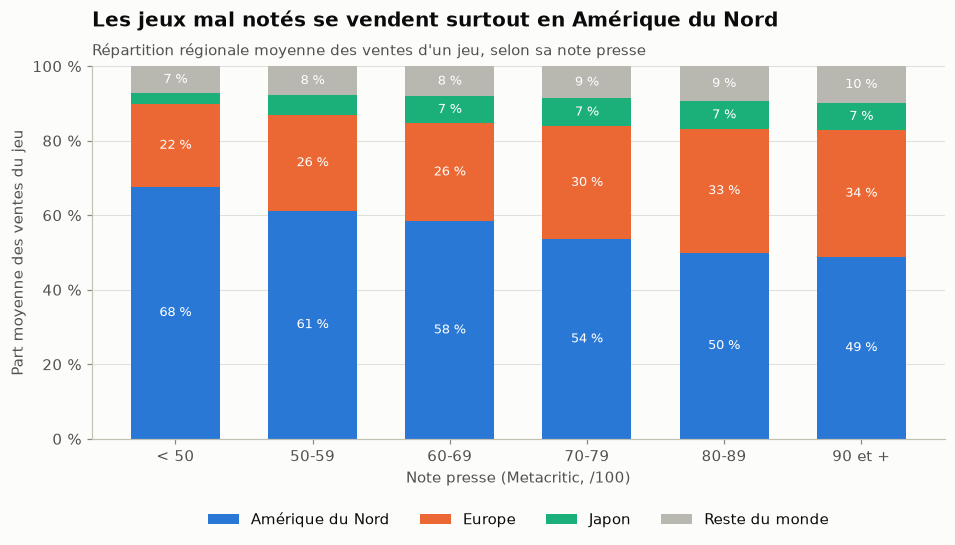

In [34]:
parts_reg = notes_v[C.REGIONS].div(notes_v[C.REGIONS].sum(axis=1), axis=0)
profil = parts_reg.groupby(notes_v["Tranche_note"], observed=True).mean()
correl_reg = pd.Series({C.REGION_LABELS[r]: np.log10(notes_v[r] + 0.01).corr(notes_v["Critic_Score"]) for r in C.REGIONS},
                       name="Corrélation note / log(ventes régionales)")
display(correl_reg.round(2).to_frame())

fig, ax = plt.subplots(figsize=(10, 4.4))
bas = np.zeros(len(profil))
for r in C.REGIONS:
    ax.bar(profil.index.astype(str), profil[r], bottom=bas, color=C.COULEURS_REGION[r], width=0.65, label=C.REGION_LABELS[r])
    for xi, (b, v) in enumerate(zip(bas, profil[r])):
        if v > 0.06:
            ax.text(xi, b + v / 2, viz.pct(v), ha="center", va="center", fontsize=8.5, color="white")
    bas += profil[r].to_numpy()
viz.format_pct(ax)
ax.set_ylim(0, 1)
ax.grid(axis="x", visible=False)
ax.set_xlabel("Note presse (Metacritic, /100)")
ax.set_ylabel("Part moyenne des ventes du jeu")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=4)
viz.titre(ax, "Les jeux mal notés se vendent surtout en Amérique du Nord",
          "Répartition régionale moyenne des ventes d'un jeu, selon sa note presse")
viz.sauver(fig, "38_jointure_regions_par_note")
plt.show()

**Lecture.** Plus un jeu est mal noté, plus ses ventes sont **concentrées en Amérique du Nord** : 68 % des ventes d'un jeu noté moins de 50, contre 49 % pour un jeu noté 90 et plus. À l'inverse, la part de l'**Europe** monte avec la note (de 22 % à 34 %). Le marché nord-américain, le plus grand, absorbe un volume important de jeux à petit budget (licences de films, jeux familiaux), alors que **l'acheteur européen est le plus sélectif** : c'est en Europe que la note est la plus liée aux ventes (corrélation 0,37, contre 0,28 en Amérique du Nord).

Le **Japon** est la région où la note compte le moins (0,24). Ce n'est pas surprenant : Metacritic agrège des critiques **occidentales**, que les joueurs japonais ne lisent pas, et beaucoup de jeux purement japonais n'ont pas de note du tout. Cela prolonge le constat de la Partie II : le Japon est un marché à part, avec ses propres prescripteurs (par exemple le magazine *Famitsu*, absent de nos données).

---
# Synthèse de la Partie V

| Question | Réponse |
|---|---|
| **Les deux bases se relient-elles ?** | Oui : 99,7 % des jeux et 99,99 % des ventes, car elles viennent du même scraping. Mais seuls 49 % des jeux (63 % des ventes) ont une note : les jeux notés sont les plus visibles. |
| **Une bonne note fait-elle vendre ?** | Les deux sont fortement liés : 13 fois plus de ventes médianes pour un jeu à 90+ que pour un jeu à moins de 50, et 62 % de hits contre 4 %. On ne peut pas parler de cause : le budget marketing explique sans doute les deux, et les jeux familiaux de Nintendo se vendent sans les critiques. |
| **La qualité change-t-elle le MPI ?** | Pas le podium (Nintendo, EA, Sony), mais la suite : les éditeurs premium (Take-Two, Bethesda, Microsoft) montent, les éditeurs de volume (THQ, Sega) descendent. |
| **Les régions réagissent-elles pareil ?** | Non. L'Europe est la plus sensible à la note, l'Amérique du Nord absorbe les jeux mal notés, et le Japon y est presque indifférent. |

**Nouvelles difficultés de data wrangling** rencontrées avec la deuxième base :

- des valeurs textuelles (`tbd`) dans une colonne numérique ;
- des **fausses correspondances introduites par la source** elle-même (remakes notés comme l'original) ;
- deux relevés de ventes différents, d'où la décision d'une **source de vérité unique** ;
- un **biais de couverture** (jeux récents, visibles, occidentaux) qui limite la portée des conclusions ;
- le besoin d'une **règle de représentativité** pour ne pas noter un éditeur sur trois jeux.